# 1.3 Phân tích đơn biến và hai biến
### NV1 : Phân tích đơn biến trên Penguins

In [1]:
import sys
print(sys.version)
print(sys.executable)

3.12.15 (main, Oct 14 2026, 01:05:27) [Clang 23.1.3 ]
/workspaces/DCT124C1-MH-Nhom/.venv/bin/python


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

penguins_data = pd.read_csv("../data/penguins_size.csv")

penguins_univariate = penguins_data[
    ['species', 'culmen_length_mm']
].copy()

print(penguins_univariate.head())
print(penguins_univariate.shape)
print(penguins_univariate.isnull().sum())

  species  culmen_length_mm
0  Adelie              39.1
1  Adelie              39.5
2  Adelie              40.3
3  Adelie               NaN
4  Adelie              36.7
(344, 2)
species             0
culmen_length_mm    2
dtype: int64


#### Phân tích đơn biến bằng Histogram

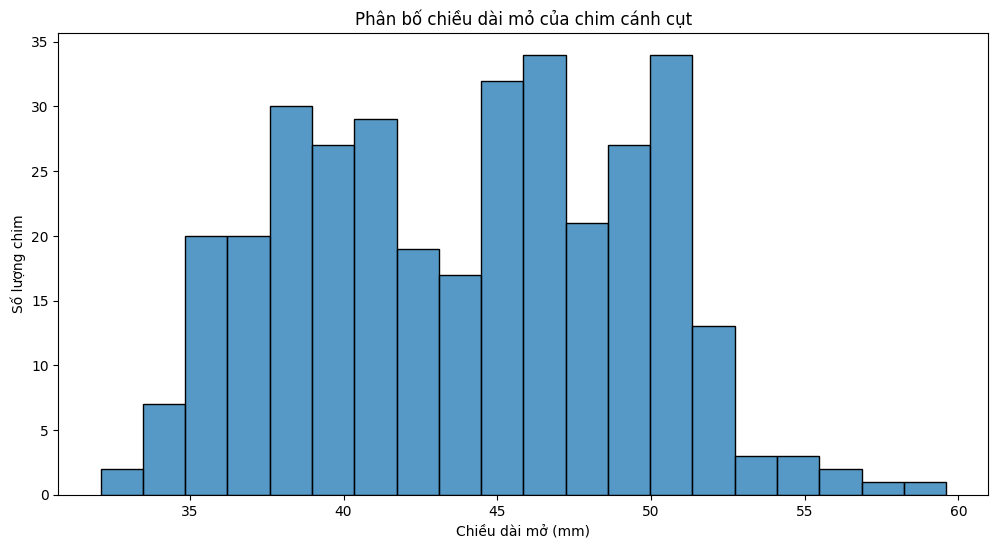

In [3]:
# Vẽ phân bố chiều dài mỏ
plt.figure(figsize=(12,6))

sns.histplot(
    data=penguins_univariate,
    x='culmen_length_mm',
    bins=20
)

plt.xlabel('Chiều dài mở (mm)')
plt.ylabel('Số lượng chim')
plt.title('Phân bố chiều dài mỏ của chim cánh cụt')
plt.show()

#### Phân tích đơn biến bằng biểu đồ cột

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


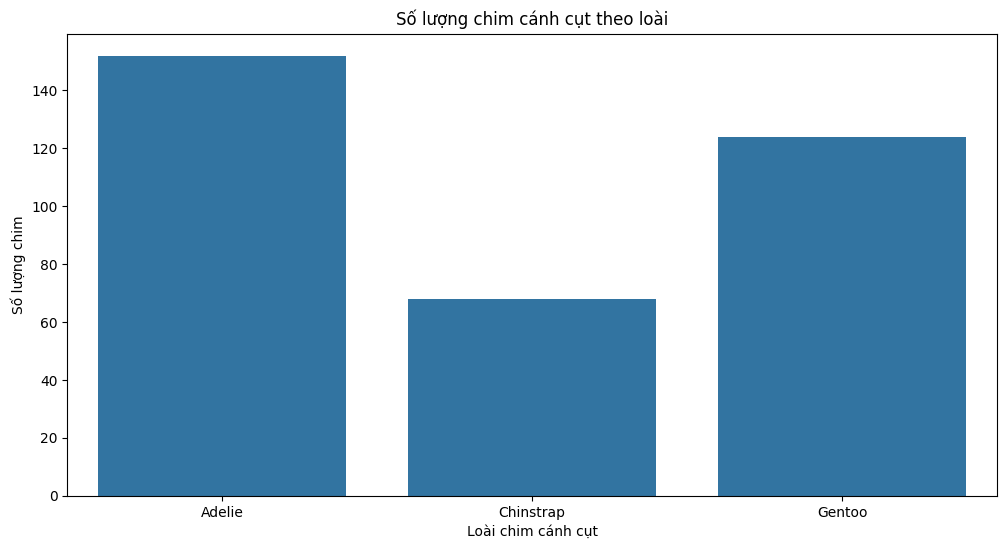

In [4]:
print(penguins_univariate['species'].value_counts())

plt.figure(figsize=(12,6))

sns.countplot(data=penguins_univariate, x='species')

plt.xlabel('Loài chim cánh cụt')
plt.ylabel('Số lượng chim')
plt.title('Số lượng chim cánh cụt theo loài')
plt.show()

#### Phân tích đơn biến bằng biểu đồ tròn

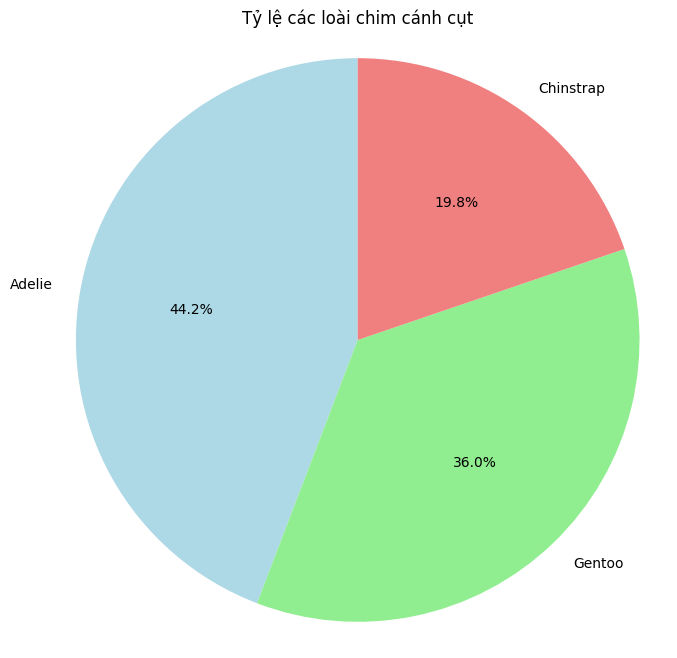

In [5]:
species_counts = penguins_univariate['species'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    species_counts.values,
    labels=species_counts.index,
    autopct='%.1f%%',
    colors=['lightblue','lightgreen','lightcoral'],
    startangle=90
)

plt.title('Tỷ lệ các loài chim cánh cụt')
plt.axis('equal')
plt.show()

### Bài toán 1 - Nhiệm vụ 2 : Phân tích đơn biến trên dữ liệu giá nhà

In [6]:
houseprices_data = pd.read_csv("../data/HousingPrices-Amsterdam-August-2021.csv")

houseprices_data = houseprices_data[['Zip','Price','Area','Room']]

print(houseprices_data.head())
print(houseprices_data.shape)
print(houseprices_data.isnull().sum())

       Zip     Price  Area  Room
0  1091 CR  685000.0    64     3
1  1059 EL  475000.0    60     3
2  1097 SM  850000.0   109     4
3  1060 TH  580000.0   128     6
4  1036 KN  720000.0   138     5
(924, 4)
Zip      0
Price    4
Area     0
Room     0
dtype: int64


#### Phân tích đơn biến giá nhà bằng Boxplot

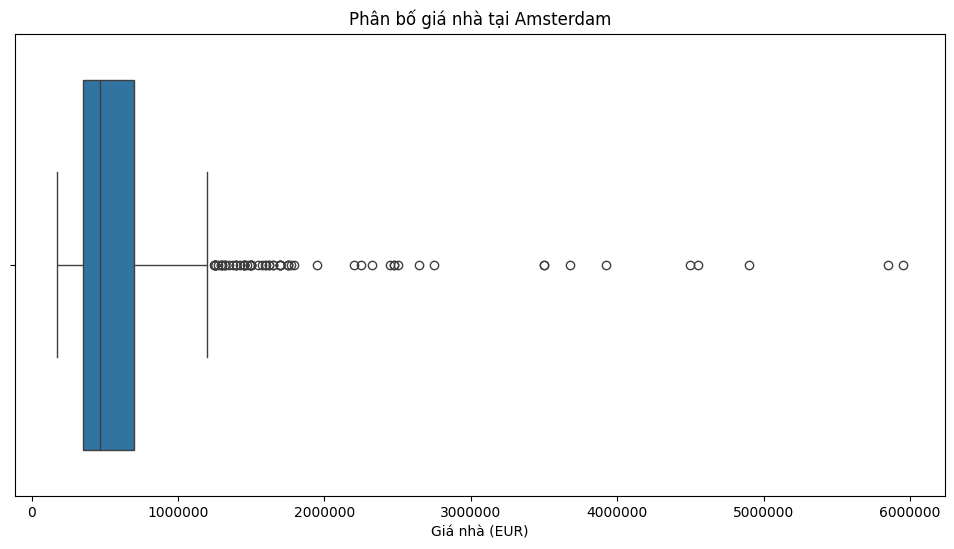

In [7]:
# Vẽ boxplot thông thường
plt.figure(figsize=(12, 6))

sns.boxplot(data=houseprices_data, x='Price')

plt.xlabel('Giá nhà (EUR)')
plt.title('Phân bố giá nhà tại Amsterdam')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

#### Phân tích đơn biến giá nhà bằng Violin Plot

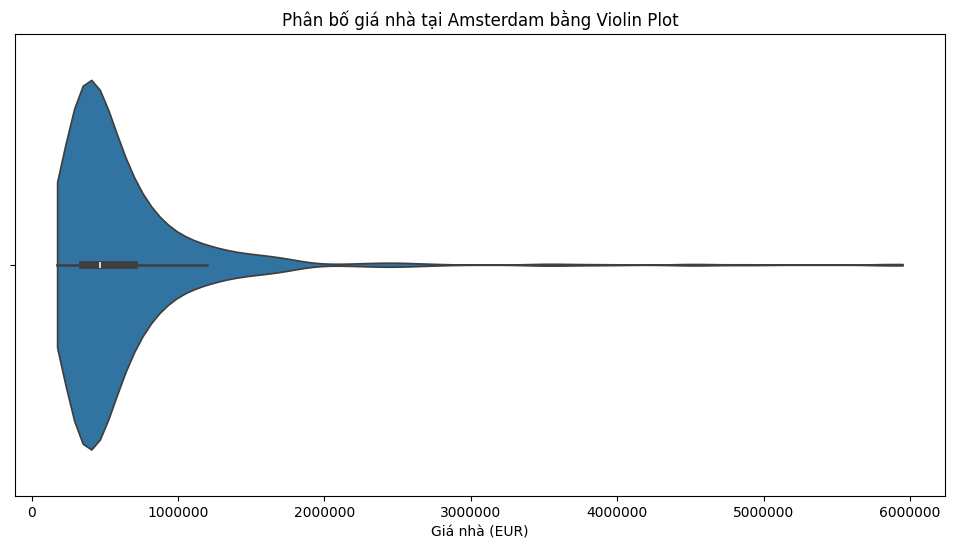

In [8]:
plt.figure(figsize=(12,6))

sns.violinplot(data=houseprices_data, x='Price', cut=0)

plt.xlabel('Giá nhà (EUR)')
plt.title('Phân bố giá nhà tại Amsterdam bằng Violin Plot')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

#### Phân tích đơn biến bằng bảng thống kê mô tả

In [9]:
houseprices_data[['Price','Area','Room']].describe().round(2)

,Price,Area,Room
count,920.00,924.00,924.00
mean,622065.42,95.95,3.57
std,538994.18,57.45,1.59
min,175000.00,21.00,1.00
25%,350000.00,60.75,3.00
50%,467000.00,83.00,3.00
75%,700000.00,113.00,4.00
max,5950000.00,623.00,14.00


### Bài toán 2: Phân tích hai biến trên Penguins
#### 1. Chuẩn bị dữ liệu

In [10]:
penguins_bivariate = penguins_data[
    ['species','culmen_length_mm','body_mass_g','sex']
].copy()

# Chuyển ký hiệu giới tính không hợp lệ thành giá trị thiếu
penguins_bivariate['sex'] = penguins_bivariate['sex'].replace('.',pd.NA)

print(penguins_bivariate.head())
print(penguins_bivariate.isnull().sum())

  species  culmen_length_mm  body_mass_g     sex
0  Adelie              39.1       3750.0    MALE
1  Adelie              39.5       3800.0  FEMALE
2  Adelie              40.3       3250.0  FEMALE
3  Adelie               NaN          NaN     NaN
4  Adelie              36.7       3450.0  FEMALE
species              0
culmen_length_mm     2
body_mass_g          2
sex                 11
dtype: int64


#### 2. Phân tích hai biến bằng Scatterplot

<function matplotlib.pyplot.show(close=None, block=None)>

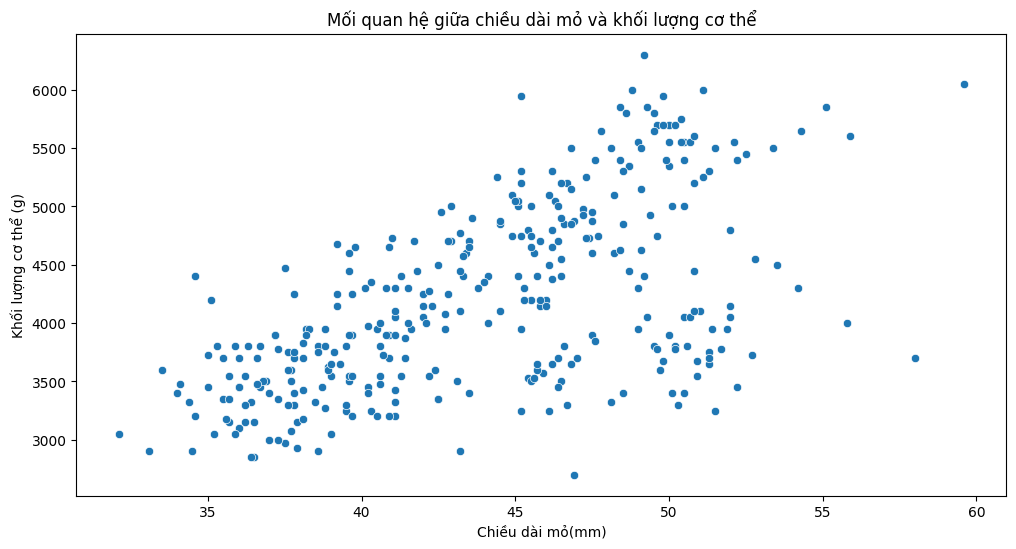

In [11]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=penguins_bivariate,
    x='culmen_length_mm',
    y='body_mass_g'
)

plt.xlabel('Chiều dài mỏ(mm)')
plt.ylabel('Khối lượng cơ thể (g)')
plt.title('Mối quan hệ giữa chiều dài mỏ và khối lượng cơ thể')
plt.show

#### 3. Phân tích hai biến bằng bảng Crosstab

In [12]:
gender_table = pd.crosstab(
    index = penguins_bivariate['species'],
    columns=penguins_bivariate['sex']
)
display(gender_table)

sex,FEMALE,MALE
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


#### 4. Phân tích hai biến bằng Pivot Table

In [13]:
mean_length = pd.pivot_table(
    penguins_bivariate,
    values='culmen_length_mm',
    index='species',
    aggfunc='mean'
)
display(mean_length.round(2))

,culmen_length_mm
species,
Adelie,38.79
Chinstrap,48.83
Gentoo,47.50


#### 5. Phân tích hai biến bằng Pairplot


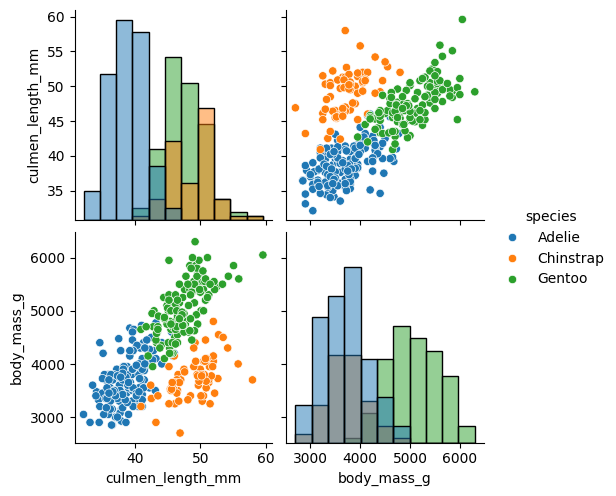

In [14]:
sns.pairplot(
    data=penguins_bivariate,
    vars=['culmen_length_mm','body_mass_g'],
    hue='species',
    diag_kind='hist'
)

plt.show()

### Bài toán 3: Khám phá dữ liệu tự động
#### Nhiệm vụ 1: Sử dụng ydata-profiling trên Marketing Campaign

In [15]:
# Nạp dữ liệu, tự nhận diện dấu phân cách
marketing_data = pd.read_csv(
    "../data/marketing_campaign.csv",
    sep=None,
    engine='python'
)

# Kiểm tra dữ liệu
print(marketing_data.shape)
print(marketing_data.columns.tolist())
display(marketing_data.head())

# Kiểm tra số giá trị thiếu
print(marketing_data.isnull().sum())

(2240, 29)
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


In [16]:
%pip install ydata-profiling

/workspaces/DCT124C1-MH-Nhom/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [17]:

from ydata_profiling import ProfileReport

/workspaces/DCT124C1-MH-Nhom/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_13465/717273786.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [18]:
from pathlib import Path

# Chuyển cột ngày đăng ký sang kiểu ngày tháng
marketing_data['Dt_Customer'] = pd.to_datetime(
    marketing_data['Dt_Customer'],
    format='%d-%m-%Y'
)

# Tạo thư mục chứa báo cáo
Path("Reports").mkdir(exist_ok=True)

# Tạo và lưu báo cáo EDA tự động
profile = ProfileReport(
    marketing_data,
    title="Marketing Campaign - EDA Report"
)

profile.to_file("Reports/marketing_profile.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 22.51it/s]


#### Nhận xét báo cáo ydata-profiling

**1. Tổng quan dữ liệu**
- Dữ liệu gồm 2.240 dòng và 29 cột.
- Công cụ nhận diện 15 biến số, 13 biến phân loại và 1 biến ngày tháng.
- Không có dòng trùng lặp khi xét toàn bộ 29 cột.
- Báo cáo ghi nhận 30 cảnh báo cần xem xét.

**2. Giá trị thiếu**
- Chỉ cột Income có dữ liệu thiếu: 24 giá trị, chiếm khoảng 1,1% số dòng.
- Các cột còn lại không có giá trị thiếu.
- Có thể cân nhắc điền Income bằng trung vị trong bước tiền xử lý.

**3. Các cảnh báo đáng chú ý**
- Z_CostContact luôn bằng 3 và Z_Revenue luôn bằng 11.
  Hai cột không có sự biến thiên, có thể loại bỏ khi xây dựng mô hình.
- ID có giá trị duy nhất cho mỗi khách hàng, phù hợp để định danh.
- Các biến AcceptedCmp1–AcceptedCmp5 và Complain bị mất cân bằng:
  số lượng giữa các nhóm chênh lệch lớn.
- Một số biến có nhiều giá trị 0, chẳng hạn NumCatalogPurchases
  có 586 giá trị 0, chiếm 26,2%. Cần hiểu ý nghĩa nghiệp vụ
  trước khi quyết định xử lý; giá trị 0 không mặc nhiên là dữ liệu lỗi.
- Công cụ cảnh báo tương quan cao giữa nhiều biến thu nhập,
  chi tiêu và số lần mua hàng. Cần xem thêm bảng tương quan
  trước khi lựa chọn đặc trưng.

**4. Phân bố và giá trị cần kiểm tra**
- Income có trung bình khoảng 52.247,25 và trung vị 51.381,50.
- Income có phân bố lệch phải mạnh, với giá trị lớn nhất 666.666;
  cần kiểm tra giá trị này trước khi quyết định giữ hoặc xử lý.
- Year_Birth có các năm 1893, 1899 và 1900, cần kiểm tra tính hợp lý.
- Marital_Status có các nhãn như Absurd và YOLO,
  cần làm rõ ý nghĩa và chuẩn hóa nếu cần.
- Các biến chi tiêu như MntWines và MntMeatProducts lệch phải:
  phần lớn khách hàng chi tiêu thấp hơn một nhóm nhỏ chi tiêu cao.

**5. Kết luận**
- ydata-profiling giúp nhanh chóng phát hiện dữ liệu thiếu,
  cột hằng, mất cân bằng, tương quan và giá trị cần kiểm tra.
- Những phát hiện này là cơ sở cho bước làm sạch và tiền xử lý dữ liệu.
- Cảnh báo tự động cần được kiểm tra theo ý nghĩa của từng biến,
  không phải cảnh báo nào cũng là lỗi dữ liệu.

In [19]:
import dtale

# Mở giao diện khám phá dữ liệu trên cổng 40000
d = dtale.show(
    marketing_data,
    host="0.0.0.0",
    port=40000,
    open_browser=False
)

print(d._main_url)

http://0.0.0.0:40000/dtale/main/1


**Nhận xét Histogram của Income:**
- Thu nhập tập trung chủ yếu ở vùng dưới 100.000.
- Phân bố lệch phải, có đuôi kéo dài về phía thu nhập cao.
- Một số giá trị lớn làm biểu đồ bị nén ở phía bên trái.
- Đường KDE màu hồng thể hiện mật độ phân bố ước lượng;
  các cột màu xanh thể hiện tần số theo từng khoảng.
- Cần kiểm tra các giá trị thu nhập quá cao trước khi xử lý ngoại lệ.

**Nhận xét ma trận tương quan Pearson trong D-Tale:**
- MntWines và AcceptedCmp5 có tương quan dương khoảng 0,47.
- MntWines và AcceptedCmp4 có tương quan dương khoảng 0,37.
- Income và AcceptedCmp5 có tương quan dương khoảng 0,34.
- Các hệ số trên cho thấy mối liên hệ tuyến tính ở mức vừa
  hoặc yếu, không thể hiện quan hệ nhân quả.

**Nhận xét tương quan giữa Income và MntWines:**
- Hệ số tương quan Pearson khoảng 0,58, thể hiện tương quan thuận mức vừa.
- Khách hàng có thu nhập cao hơn thường có xu hướng chi tiêu
  cho rượu vang nhiều hơn, nhưng vẫn có sự khác biệt giữa các khách hàng.
- Các giá trị thu nhập cực lớn có thể ảnh hưởng đến hệ số Pearson.
- Tương quan không đủ để kết luận quan hệ nhân quả.

### 1.3.3. Bài tập thực hành 1: SweetViz
Khám phá dữ liệu Marketing Campaign bằng SweetViz.

In [20]:
import sweetviz as sv
from pathlib import Path

# Tạo thư mục lưu báo cáo
Path("Reports").mkdir(exist_ok=True)

# Phân tích dữ liệu Marketing Campaign
sweet_report = sv.analyze(marketing_data)

# Xuất báo cáo HTML
sweet_report.show_html(
    "Reports/marketing_sweetviz.html",
    open_browser=False
)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)

Report Reports/marketing_sweetviz.html was generated.


#### Tính năng và cách sử dụng SweetViz
- Dùng sv.analyze(marketing_data) để phân tích dữ liệu.
- Dùng show_html() để xuất báo cáo HTML.
- Báo cáo cung cấp tổng quan, thống kê từng biến, phân bố,
  giá trị thiếu và mối liên hệ giữa các biến.

#### Nhận xét kết quả
- Dữ liệu gồm 2.240 dòng và 29 biến, không có dòng trùng lặp.
- SweetViz nhận diện 15 biến số, 13 biến phân loại và 1 biến
  văn bản. Trong báo cáo này, Dt_Customer được xếp vào nhóm văn bản.
- Income thiếu 24 giá trị, tương đương khoảng 1,07% số dòng.
- Income có độ lệch khoảng 6,76, thể hiện phân bố lệch phải mạnh.
  Giá trị lớn nhất là 666.666, cần kiểm tra thêm.
- Nhóm Education phổ biến nhất là Graduation:
  1.127 khách hàng, khoảng 50,3%.
- Income tương quan thuận với MntWines (Pearson ≈ 0,58)
  và tương quan nghịch với NumWebVisitsMonth (≈ -0,55).
- MntMeatProducts và NumCatalogPurchases có tương quan
  thuận khá mạnh (Pearson ≈ 0,72).
- Z_CostContact và Z_Revenue mỗi cột chỉ có một giá trị duy nhất.
- Các hệ số liên hệ trong Associations sử dụng độ đo khác nhau
  tùy loại biến; không phải tất cả đều là Pearson.
- Các mối liên hệ trên không đủ để kết luận quan hệ nhân quả.

### 1.3.4. Bài tập thực hành 2: AutoViz
Tìm hiểu công cụ tự động trực quan hóa dữ liệu Marketing Campaign.

In [21]:
from autoviz.AutoViz_Class import AutoViz_Class

# Khởi tạo công cụ AutoViz
AV = AutoViz_Class()

# Tự động tạo và lưu biểu đồ từ dữ liệu Marketing
autoviz_data = AV.AutoViz(
    filename="",
    dfte=marketing_data.copy(),
    depVar="",
    verbose=2,
    chart_format="png",
    max_rows_analyzed=2240,
    max_cols_analyzed=30,
    save_plot_dir="Reports/AutoViz"
)

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (2240, 29)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
  Printing up to 30 columns (max) in each category:
    Numeric Columns : ['Income']
    Integer-Categorical Columns: ['Year_Birth', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'Nu

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
ID,int64,0.000000,100,0.000000,11191.000000,Possible ID column: drop before modeling step.
Year_Birth,int64,0.000000,2,1893.000000,1996.000000,Column has 3 outliers greater than upper bound (2004.00) or lower than lower bound(1932.00). Cap them or remove them.
Education,object,0.000000,0,,,No issue
Marital_Status,object,0.000000,0,,,"3 rare categories: ['Alone', 'YOLO', 'Absurd']. Group them into a single category or drop the categories."
Income,float64,1.071429,NA,1730.000000,666666.000000,"24 missing values. Impute them with mean, median, mode, or a constant value such as 123., Column has 8 outliers greater than upper bound (118350.50) or lower than lower bound(-14525.50). Cap them or remove them."
Kidhome,int64,0.000000,0,0.000000,2.000000,No issue
Teenhome,int64,0.000000,0,0.000000,2.000000,No issue
Dt_Customer,datetime64[ns],0.000000,29,,,Possible date-time colum: transform before modeling step.
Recency,int64,0.000000,4,0.000000,99.000000,No issue
MntWines,int64,0.000000,34,0.000000,1493.000000,Column has 35 outliers greater than upper bound (1225.00) or lower than lower bound(-697.00). Cap them or remove them.


Could not draw Date Vars cannot write empty image
All Plots are saved in Reports/AutoViz/AutoViz
Time to run AutoViz = 15 seconds 


#### Tính năng và cách sử dụng AutoViz
- AutoViz tự động lựa chọn và tạo biểu đồ từ DataFrame.
- Công cụ hỗ trợ xem phân bố, so sánh các nhóm,
  phát hiện giá trị bất thường và phân tích tương quan.
- Sử dụng verbose=2 để lưu biểu đồ và chart_format="png"
  để xuất ảnh vào thư mục Reports/AutoViz.

#### Nhận xét kết quả

**1. Phân bố các nhóm**
- Các biến AcceptedCmp1–AcceptedCmp5 có nhóm 0 chiếm đa số,
  cho thấy số khách hàng chấp nhận từng chiến dịch khá ít.
- Response có nhóm 0 chiếm khoảng 85%, nhóm 1 khoảng 15%.
- Education có nhóm Graduation chiếm tỷ lệ lớn nhất.
- Marital_Status có nhóm Married chiếm tỷ lệ lớn nhất.
- Một số biểu đồ chỉ hiển thị 15 giá trị phổ biến nhất,
  không thể hiện toàn bộ giá trị của biến.

**2. Thu nhập trung bình theo nhóm**
- Nhóm PhD có thu nhập trung bình cao nhất trong các nhóm học vấn;
  nhóm Basic có thu nhập trung bình thấp nhất.
- Nhóm không có trẻ nhỏ (Kidhome=0) có thu nhập trung bình
  cao hơn các nhóm Kidhome=1 và Kidhome=2.
- Nhóm chấp nhận chiến dịch 1 và 5 có thu nhập trung bình
  cao hơn nhóm không chấp nhận.
- Cần xét thêm số lượng mẫu từng nhóm trước khi kết luận,
  đặc biệt với những nhóm ít khách hàng.

**3. Phân bố và ngoại lệ của Income**
- Histogram cho thấy thu nhập tập trung chủ yếu dưới 100.000.
- Phân bố lệch phải mạnh, với độ lệch khoảng 6,8.
- Boxplot cho thấy một số giá trị thu nhập cao bất thường,
  nổi bật là giá trị gần 666.666.
- Probability Plot và Violin Plot cũng cho thấy đuôi trên kéo dài.
- Cần kiểm tra các giá trị cực lớn trước khi quyết định xử lý.

**4. Ma trận tương quan**
- Trong heatmap này, Income và MntWines có tương quan
  thuận khoảng 0,60.
- MntMeatProducts và NumCatalogPurchases có tương quan
  thuận khá mạnh, khoảng 0,74.
- Income và NumWebVisitsMonth có tương quan nghịch,
  khoảng -0,56.
- Z_CostContact và Z_Revenue có vùng trống vì là cột hằng;
  hệ số tương quan Pearson không xác định.
- Tương quan không đủ để kết luận quan hệ nhân quả.